# Chapitre 1 - Exercices 1.1 à 1.6

Ce notebook traite les six premiers exercices du chapitre 1, centrés sur la charge et
la performance :

- **1.1** : ordres de grandeur du fan-out, seuil lectures/écritures et rattrapage
  d'un pic (calcul) ;
- **1.2** : où placer le seuil de l'approche hybride ? (calcul et mini-lab) ;
- **1.3** : percentiles à la main, et pourquoi on additionne des histogrammes
  (calcul) ;
- **1.4** : amplification de la latence de queue et requêtes de couverture (calcul et
  simulation) ;
- **1.5** : échantillonnage par réservoir contre histogramme pour estimer des
  percentiles en flux (mini-lab) ;
- **1.6** : loi de Little et dimensionnement d'un pool de connexions (calcul).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 1.1 : ordres de grandeur du fan-out

**Énoncé.** Un réseau social compte 50 millions d'utilisateurs actifs par jour. Chacun
publie en moyenne 2 messages et consulte sa timeline 30 fois par jour ; un compte suit en
moyenne 150 comptes.

1. Quel est le nombre moyen d'abonnés par compte ? Calculer les débits moyens de
   publications et de lectures de timeline (par seconde).
2. Calculer le nombre d'opérations élémentaires par seconde pour la timeline calculée à
   la lecture et pour la timeline matérialisée (fan-out à l'écriture).
3. Montrer que, dans ce modèle, le fan-out à l'écriture fait moins d'opérations que le
   calcul à la lecture **si et seulement si** on lit plus souvent qu'on ne publie.
4. Lors d'un événement, les publications sont multipliées par 10 pendant 20 minutes.
   L'infrastructure de fan-out a une capacité égale à **deux fois** le débit moyen
   d'écritures de fan-out, et les livraisons en retard sont mises en file d'attente.
   Quel retard maximal subit une livraison ? Combien de temps faut-il pour résorber la
   file ?

**Rappels.** Lecture : `lectures × abonnements` accès ; écriture :
`publications × abonnés` écritures et une lecture par consultation. Dans un graphe
fermé, abonnés moyens = abonnements moyens (cours 1, section 2, section *Describing Load*).

**Solution.**

*1.* Chaque arête « A suit B » compte un abonnement pour A et un abonné pour B : le
nombre moyen d'abonnés vaut donc aussi **150**. Débits : $P = 50 \cdot 10^6 \times 2 / 86\,400
\approx 1\,157$ publications/s et $R = 50 \cdot 10^6 \times 30 / 86\,400 \approx 17\,361$
lectures/s.

*2.* À la lecture : $P + R \times 150 \approx 1\,157 + 2\,604\,000 \approx 2{,}6$ millions
d'opérations/s. À l'écriture : $P \times 150 + R \approx 173\,600 + 17\,361 \approx 191\,000$
opérations/s, quatorze fois moins.

*3.* Avec $F$ abonnés (= abonnements) moyens : écriture $PF + R$, lecture $P + RF$.
$PF + R < P + RF \iff (F-1)(P - R) < 0 \iff R > P$ (pour $F > 1$). Le fan-out gagne dès
qu'on lit plus qu'on ne publie, quel que soit $F$ ; l'écart, lui, croît avec $F$.

*4.* Débit moyen de fan-out $D = 173\,600$ écritures/s, capacité $C = 2D$. Pendant le pic
(1 200 s), la demande vaut $10D$ : la file grossit de $8D$ par seconde, jusqu'à
$8D \times 1\,200 \approx 1{,}67 \cdot 10^9$ écritures. Une livraison déposée en dernier
attend que toute la file devant elle soit traitée, soit $1{,}67 \cdot 10^9 / C = 4\,800$ s
= **80 minutes** de retard. Après le pic, la file se vide à la vitesse $C - D = D$ :
$8D \times 1\,200 / D = 9\,600$ s, soit **2 h 40** pour revenir à la normale.

**Vérification numérique** : calcul direct, puis simulation seconde par seconde de la
file de fan-out (modèle fluide), avec le retard d'une livraison déposée à chaque instant.

P = 1157 publications/s ; R = 17361 lectures/s
à la lecture : 2 605 324 op/s ; à l'écriture : 190 972 op/s ; rapport 13.6


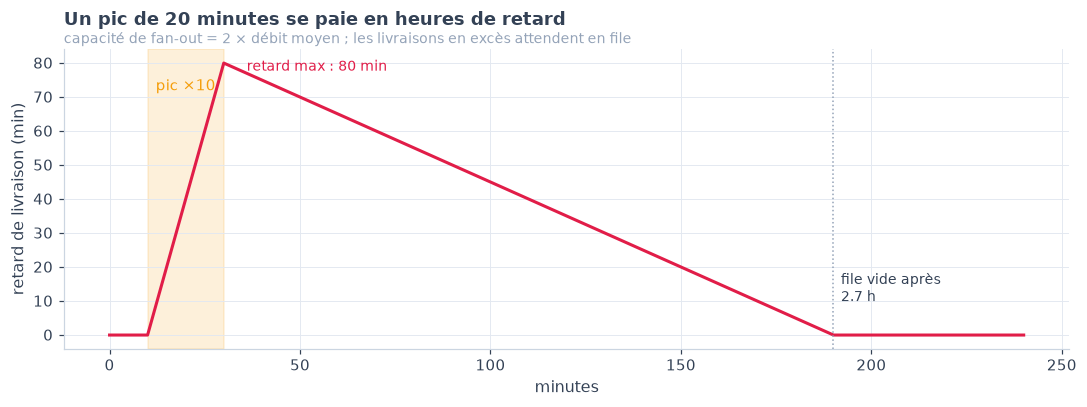

In [2]:
actifs, pub_j, lec_j, F = 50e6, 2, 30, 150
P, R = actifs * pub_j / 86400, actifs * lec_j / 86400
print(f"P = {P:.0f} publications/s ; R = {R:.0f} lectures/s")
print(f"à la lecture : {fmt(P + R * F)} op/s ; à l'écriture : {fmt(P * F + R)} op/s ; rapport {(P + R * F) / (P * F + R):.1f}")

D = P * F
C = 2 * D
T = 4 * 3600
t = np.arange(T)
demande = np.where((t >= 600) & (t < 1800), 10 * D, D)
file = np.zeros(T)
for s in range(1, T):
    file[s] = max(0.0, file[s - 1] + demande[s] - C)
retard = file / C                                   # FIFO : temps pour écouler la file devant soi
fin = t[(t > 1800) & (file == 0)][0]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t / 60, retard / 60, color=ROSE, lw=2)
ax.axvspan(10, 30, color=AMBER, alpha=0.15); ax.text(20, retard.max() / 60 * 0.9, "pic ×10", ha="center", color=AMBER)
ax.annotate(f"retard max : {retard.max() / 60:.0f} min", (30, retard.max() / 60), (15, -5), textcoords="offset points",
            fontsize=9, color=ROSE)
ax.axvline(fin / 60, color=GRAY, ls=":", lw=1)
ax.text(fin / 60 + 2, 10, f"file vide après\n{(fin - 1800) / 3600:.1f} h", fontsize=9, color=SLATE)
ax.set_xlabel("minutes"); ax.set_ylabel("retard de livraison (min)")
ax.set_title("Un pic de 20 minutes se paie en heures de retard")
subtitle(ax, "capacité de fan-out = 2 × débit moyen ; les livraisons en excès attendent en file")
plt.tight_layout(); plt.show()

La simulation retrouve les 80 minutes de retard et les 2 h 40 de rattrapage. Les lectures
restent rapides pendant tout ce temps (on sert des timelines un peu périmées depuis le
cache), mais un message publié au pic de l'événement n'atteint ses abonnés qu'une heure
et demie plus tard : c'est le prix d'une capacité dimensionnée pour la moyenne.

> **À retenir.** Le fan-out à l'écriture gagne dès que les lectures sont plus fréquentes
> que les écritures. Un pic d'écritures peut être absorbé par une file, mais le retard
> accumulé vaut (excès × durée) / capacité, et le rattrapage dépend de la marge
> capacité - débit moyen.

## Exercice 1.2 : où placer le seuil de l'approche hybride ?

**Énoncé.** On reprend le coût par compte du cours 1 : un compte de $F$ abonnés qui
publie $p$ messages par seconde coûte $w\,p\,F$ s'il est diffusé (une écriture dispersée
coûte $w$ unités) et $r\,F$ s'il ne l'est pas (chacun de ses $F$ abonnés relit sa liste
de messages, en mémoire, à chacune de ses $r$ lectures par seconde ; coût unitaire 1).

1. On suppose d'abord que tous les comptes publient au même rythme $p$. Montrer que la
   décision de diffuser ne dépend pas de $F$. Qu'en conclure sur l'approche hybride ?
2. En réalité les comptes populaires publient plus. On pose $p(F) = p_0\,(F/F_m)^{\beta}$,
   où $F_m$ est le nombre médian d'abonnés. Montrer qu'il existe un seuil $F^*$ au-delà
   duquel il vaut mieux ne pas diffuser, et l'exprimer.
3. Application : $p_0$ = 1 message par jour, $r$ = 20 lectures par jour, $\beta = 0{,}5$,
   graphe de 50 000 comptes de `rq.social_graph` (graine 2). Calculer $F^*$ pour $w = 1$
   et $w = 5$, puis le vérifier en balayant le seuil avec `rq.fanout_costs`.
4. On impose en plus qu'un message soit livré à tous ses abonnés en moins de 5 s avec
   une capacité de 1 000 insertions par seconde allouées à un message. Quel seuil
   retenir ?

**Rappels.** Coûts des stratégies, loi de puissance des abonnés et approche hybride :
cours 1, sections 4 et 5 (section *Describing Load*).

**Solution.**

*1.* Diffuser coûte moins cher si $w\,p\,F < r\,F \iff w\,p < r$ : $F$ se simplifie. Le
choix est le même pour **tous** les comptes : tout diffuser (si $wp < r$) ou ne rien
diffuser. Un seuil sur le nombre d'abonnés n'a pas de justification dans ce modèle de
coût moyen linéaire ; il en faut une autre (rythme de publication lié à la popularité,
contrainte de pire cas).

*2.* La condition de diffusion devient $w\,p_0 (F/F_m)^\beta < r$, soit
$$F < F^* = F_m \left(\frac{r}{w\,p_0}\right)^{1/\beta}.$$
Au-delà de $F^*$, le compte publie tellement que lui faire relire ses messages par ses
abonnés coûte moins cher que les leur livrer.

*3.* Avec $r/p_0 = 20$ et $\beta = 0{,}5$ : $F^* = F_m \times (20/w)^2$, soit $400\,F_m$
pour $w = 1$ et $16\,F_m$ pour $w = 5$. Le médian $F_m$ du graphe est calculé ci-dessous.

*4.* Livrer $F$ insertions en 5 s à 1 000 insertions/s impose $F \le 5\,000$. Le seuil
retenu est $\min(F^*, 5\,000)$.

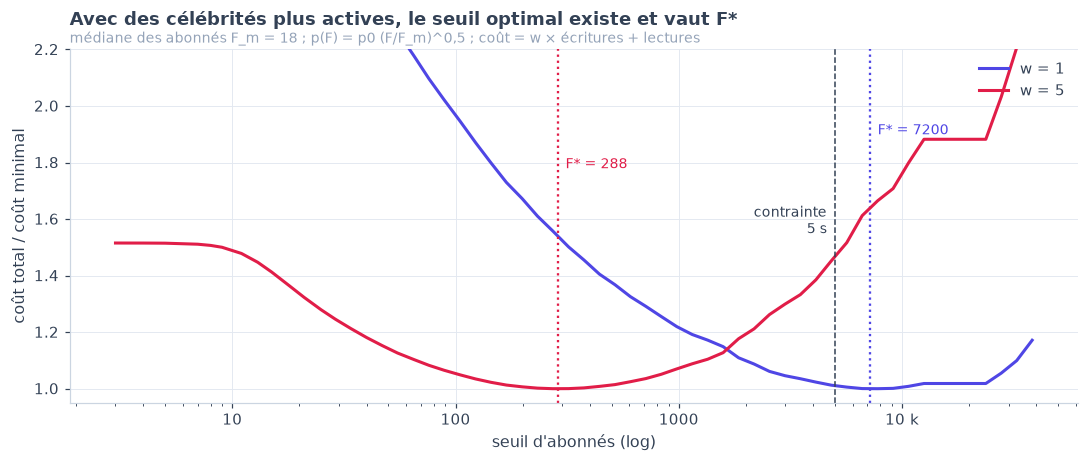

,F_star_theorique,seuil_optimal_balayage,seuil_retenu_avec_contrainte
1,7200.0,7776.0,5000.0
5,288.0,273.0,288.0


In [3]:
N = 50_000
fb, gb = rq.social_graph(N, mean_follows=50, alpha=1.2, seed=2)
nf, _ = rq.degree_counts(fb, gb, N)
Fm = float(np.median(nf))
p0, r, beta = 1 / 86400, 20 / 86400, 0.5
p_u = p0 * (np.maximum(nf, 1) / Fm) ** beta
seuils = np.unique(np.logspace(0.5, np.log10(nf.max() + 2), 60).astype(int))
fig, ax = plt.subplots(figsize=(10, 4.3))
res = {}
for w, c in [(1, INDIGO), (5, ROSE)]:
    tot = []
    for s_ in seuils:
        cst = rq.fanout_costs(fb, gb, N, p_u, r, threshold=s_)
        tot.append(w * cst["hybride_ecritures"] + cst["hybride_lectures"])
    tot = np.array(tot)
    F_star = Fm * (r / (w * p0)) ** (1 / beta)
    res[w] = dict(F_star_theorique=F_star, seuil_optimal_balayage=seuils[tot.argmin()])
    ax.plot(seuils, tot / tot.min(), color=c, label=f"w = {w}")
    ax.axvline(F_star, color=c, ls=":", lw=1.5)
    ax.text(F_star * 1.08, 1.9 - 0.12 * (w == 5), f"F* = {F_star:.0f}", color=c, fontsize=9)
ax.axvline(5_000, color=SLATE, ls="--", lw=1)
ax.text(5_000 * 0.92, 1.55, "contrainte\n5 s", color=SLATE, fontsize=9, ha="right")
ax.set_xscale("log"); rq.plain_log_axis(ax, "x")
ax.set_ylim(0.95, 2.2)
ax.set_xlabel("seuil d'abonnés (log)"); ax.set_ylabel("coût total / coût minimal")
ax.set_title("Avec des célébrités plus actives, le seuil optimal existe et vaut F*")
subtitle(ax, f"médiane des abonnés F_m = {Fm:.0f} ; p(F) = p0 (F/F_m)^0,5 ; coût = w × écritures + lectures")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
pd.DataFrame(res).T.assign(seuil_retenu_avec_contrainte=lambda df: np.minimum(df.F_star_theorique, 5_000)).round(0)

Le balayage numérique retrouve le seuil théorique (à la granularité près des seuils
testés et des marches de la distribution). Avec $w = 1$, $F^*$ dépasse la contrainte de
pire cas : c'est la contrainte de 5 s qui fixe le seuil à 5 000. Avec $w = 5$ (écritures
dispersées chères), le coût moyen à lui seul justifie un seuil bas. Notez la platitude
des courbes autour de l'optimum : le choix exact du seuil importe peu, son ordre de
grandeur beaucoup.

> **À retenir.** Sous un coût linéaire uniforme, un seuil de popularité ne se justifie
> pas ; il apparaît dès que les comptes populaires publient plus ($F^* = F_m (r/wp_0)^{1/\beta}$)
> ou qu'on borne le pire cas d'une diffusion.

## Exercice 1.3 : percentiles à la main, et pourquoi on additionne des histogrammes

**Énoncé.**

1. Voici 20 temps de réponse (ms) :
   `12 15 11 14 250 13 16 12 18 13 15 900 14 12 17 13 16 15 14 19`.
   Calculer la moyenne, la médiane, le p90 et le p95 (méthode du rang le plus proche :
   la valeur de rang $\lceil q \cdot n / 100 \rceil$ dans la liste triée). Que se
   passe-t-il si l'on retire la valeur 900 ?
2. Deux serveurs résument leurs temps de réponse de la journée par un histogramme :

   | seau (ms) | 0-20 | 20-50 | 50-100 | 100-500 | 500-1000 | 1000-2000 | 2000-5000 |
   |---|---|---|---|---|---|---|---|
   | serveur A | 600 | 291 | 9 | 0 | 0 | 0 | 0 |
   | serveur B | 50 | 30 | 5 | 5 | 5 | 4 | 1 |

   Dans quel seau se trouve le p99 de chaque serveur ? Le p99 global ? Comparer à la
   moyenne (simple, puis pondérée par le nombre de requêtes) des p99 des serveurs.

**Rappels.** Médiane, percentiles, valeurs aberrantes ; agrégation par somme
d'histogrammes (cours 2, sections 3 et 4 ; section *Describing Performance* et encadré *Percentiles in Practice*).

**Solution.**

*1.* Liste triée : 11, 12, 12, 12, 13, 13, 13, 14, 14, 14, 15, 15, 15, 16, 16, 17, 18, 19,
250, 900. Somme = 1 409, moyenne = **70,5 ms** ; médiane = rang 10 = **14 ms** ; p90 =
rang 18 = **19 ms** ; p95 = rang 19 = **250 ms**. Sans la valeur 900 (19 valeurs), la
moyenne tombe à 26,8 ms : une seule requête la multipliait par 2,6, alors que la médiane
(rang 10 : 14 ms) ne bouge pas. Le p95 (rang 19 : 250 ms) dépend, lui, de la queue :
c'est son rôle.

*2.* Serveur A (900 requêtes) : le p99 est la 891e valeur ; cumul 600, 891 : elle est
dans le seau **20-50 ms**. Serveur B (100 requêtes) : 99e valeur ; cumul 50, 80, 85,
90, 95, 99 : seau **1 000-2 000 ms**. Global (1 000 requêtes) : la 990e valeur ; seaux
additionnés 650, 321, 14, 5, 5, 4, 1, cumul 650, 971, 985, **990** : seau **100-500 ms**.

La moyenne simple des p99 (≈ 25 à 50 ms et 1 000 à 2 000 ms) donne de l'ordre de 500 à
1 000 ms, la moyenne pondérée de l'ordre de 120 à 250 ms : rien ne garantit que l'une ou
l'autre tombe dans le bon seau (ici, aucune des deux n'y tombe). Seule la somme des
histogrammes donne le bon résultat.

In [4]:
x = np.array([12, 15, 11, 14, 250, 13, 16, 12, 18, 13, 15, 900, 14, 12, 17, 13, 16, 15, 14, 19], float)
tab = pd.DataFrame({"avec 900": [x.mean()] + [rq.percentile(x, q) for q in (50, 90, 95)],
                    "sans 900": [x[x != 900].mean()] + [rq.percentile(x[x != 900], q) for q in (50, 90, 95)]},
                   index=["moyenne", "médiane", "p90", "p95"])
print(tab.round(1))

bords = [0, 20, 50, 100, 500, 1000, 2000, 5000]
hA = [600, 291, 9, 0, 0, 0, 0]
hB = [50, 30, 5, 5, 5, 4, 1]
def tirer(h, seed):          # valeurs uniformes dans chaque seau, pour vérifier
    g = np.random.default_rng(seed)
    return np.concatenate([g.uniform(bords[i], bords[i + 1], c) for i, c in enumerate(h)])
vA, vB = tirer(hA, 1), tirer(hB, 2)
p99A, p99B, p99 = rq.percentile(vA, 99), rq.percentile(vB, 99), rq.percentile(np.concatenate([vA, vB]), 99)
pd.DataFrame({"p99 (ms)": [p99A, p99B, (p99A + p99B) / 2, 0.9 * p99A + 0.1 * p99B, p99]},
             index=["serveur A", "serveur B", "moyenne simple des p99", "moyenne pondérée", "p99 global exact"]).round(0)

         avec 900  sans 900
moyenne      70.4      26.8
médiane      14.0      14.0
p90          19.0      19.0
p95         250.0     250.0


,p99 (ms)
serveur A,50.0
serveur B,1523.0
moyenne simple des p99,787.0
moyenne pondérée,197.0
p99 global exact,431.0


Avec des valeurs tirées uniformément dans chaque seau, le p99 global tombe bien dans le
seau 100-500 ms, alors que la moyenne simple des p99 est presque deux fois trop grande
et la moyenne pondérée plus de deux fois trop petite. On
voit aussi pourquoi les systèmes de supervision exportent des **compteurs par seau** :
c'est la seule représentation qui s'additionne.

> **À retenir.** La médiane résiste aux valeurs aberrantes, la moyenne non. Un percentile
> global se lit sur la **somme des histogrammes**, jamais sur une moyenne de percentiles.

## Exercice 1.4 : amplification de la latence de queue et requêtes de couverture

**Énoncé.** Une page est construite à partir de 40 appels parallèles à un service
interne dont le temps de réponse a une médiane de 40 ms et un p99 d'environ 750 ms
(distribution de `rq.synthetic_response_times`).

1. Quelle fraction des pages attend au moins un appel plus lent que le p99 du service ?
2. Quel percentile chaque appel devrait-il garantir pour que 99 % des pages n'attendent
   aucun appel au-delà du seuil correspondant ?
3. **Requête de couverture** (hedged request) : si un appel n'a pas répondu au bout d'un
   délai $d$ égal au p95 du service, on envoie une copie à une autre réplique et on
   prend la première réponse. En supposant les deux temps indépendants, exprimer
   $P(R > t)$ pour $t > d$, et le surcoût en nombre d'appels.
4. Simuler : p99 d'un appel et p99 d'une page, avec et sans couverture.

**Rappels.** $P(\text{lente}) = 1 - (1-p)^n$ ; quantile par appel $q^{1/n}$ (cours 2,
section 5 ; section *Describing Performance*).

**Solution.**

*1.* $1 - 0{,}99^{40} \approx 33\,\%$ des pages : une sur trois.

*2.* $0{,}99^{1/40} \approx 0{,}99975$ : chaque appel devrait tenir son **p99,975**.

*3.* Notons $X_1$ le temps du premier appel, $X_2$ celui de la copie (lancée à $d$). La
réponse arrive à $R = \min(X_1, d + X_2)$. Pour $t > d$ :
$$P(R > t) = P(X_1 > t)\, P(X_2 > t - d).$$
Pour $t$ grand devant $d$, c'est à peu près le **carré** de la probabilité d'origine :
la queue est écrasée. Le surcoût : on n'envoie une copie que si $X_1 > d$, soit dans 5 %
des cas (puisque $d$ est le p95), donc **5 % d'appels en plus**.

1 - 0,99^40 = 33.1% ; quantile par appel = 0.99975
délai de couverture d = p95 = 90 ms ; appels supplémentaires = 5.0%


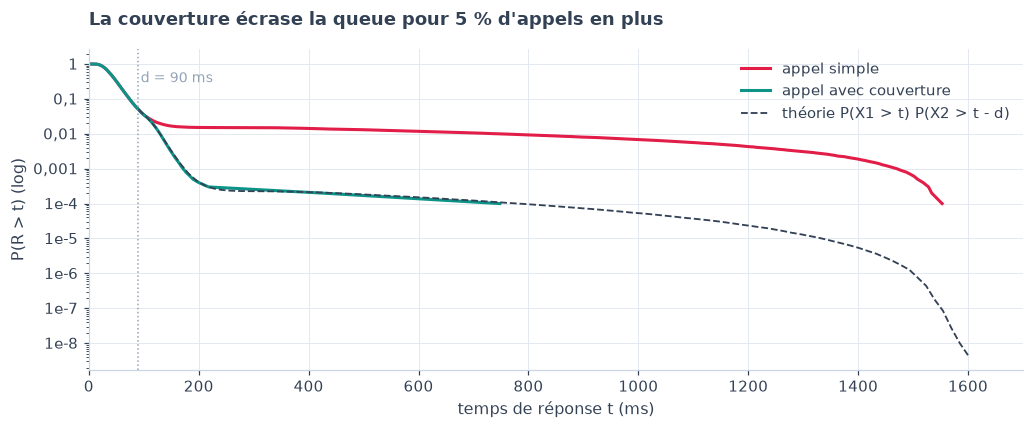

,sans couverture,avec couverture
appel : p50,40.0,40.0
appel : p99,748.0,130.0
page (40 appels) : p50,143.0,119.0
page : p99,1532.0,424.0


In [5]:
svc = rq.synthetic_response_times(400_000, seed=5)
d = np.percentile(svc, 95)
g = np.random.default_rng(6)
x1, x2 = g.choice(svc, 400_000), g.choice(svc, 400_000)
hedge = np.minimum(x1, d + x2)
surcout = (x1 > d).mean()

def page(samples, n=40, pages=20_000, seed=0):
    idx = np.random.default_rng(seed).integers(0, samples.size, (pages, n))
    return samples[idx].max(axis=1)

p_sans, p_avec = page(x1), page(hedge)
tab = pd.DataFrame({"sans couverture": [np.percentile(x1, 50), np.percentile(x1, 99), np.percentile(p_sans, 50),
                                         np.percentile(p_sans, 99)],
                    "avec couverture": [np.percentile(hedge, 50), np.percentile(hedge, 99), np.percentile(p_avec, 50),
                                         np.percentile(p_avec, 99)]},
                   index=["appel : p50", "appel : p99", "page (40 appels) : p50", "page : p99"])
print(f"1 - 0,99^40 = {rq.p_any_slow(0.01, 40):.1%} ; quantile par appel = {rq.per_call_quantile_for(0.99, 40):.5f}")
print(f"délai de couverture d = p95 = {d:.0f} ms ; appels supplémentaires = {surcout:.1%}")

fig, ax = plt.subplots(figsize=(9.5, 4))
for data, c, nom in [(x1, ROSE, "appel simple"), (hedge, TEAL, "appel avec couverture")]:
    xs = np.sort(data)[::40]
    ax.semilogy(xs, 1 - np.arange(1, xs.size + 1) / xs.size + 1 / xs.size, color=c, label=nom)
ax.axvline(d, color=GRAY, ls=":", lw=1); ax.text(d * 1.05, 0.3, f"d = {d:.0f} ms", color=GRAY, fontsize=9)
tt = np.linspace(d, 1600, 100)
surv = lambda v: (svc[:, None] > v).mean(axis=0)
ax.semilogy(tt, surv(tt) * surv(tt - d), "--", color=SLATE, lw=1.2, label="théorie P(X1 > t) P(X2 > t - d)")
rq.plain_log_axis(ax, "y")
ax.set_xlim(0, 1700); ax.set_xlabel("temps de réponse t (ms)"); ax.set_ylabel("P(R > t) (log)")
ax.set_title("La couverture écrase la queue pour 5 % d'appels en plus")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
tab.round(0)

La simulation suit la formule. Le p99 d'un appel est divisé par plus de cinq, et celui de
la page à 40 appels par plus de trois (de 1,5 s à 0,4 s). Le surcoût est de 5 % d'appels : un compromis
remarquable, à condition que les lenteurs soient bien **indépendantes** d'une réplique à
l'autre (une requête intrinsèquement coûteuse sera lente partout, et la couverture
doublera inutilement son coût).

> **À retenir.** Avec $n$ appels parallèles, la queue de chaque appel devient la norme
> ($1-(1-p)^n$). Les requêtes de couverture coupent la queue (probabilités qui se
> multiplient) pour un surcoût égal à la fraction d'appels plus lents que le délai choisi.